Total images found: 614

--- Dataset Statistics Summary (Sample of 50 images) ---
             Width       Height      R_mean      G_mean      B_mean
count    50.000000    50.000000   50.000000   50.000000   50.000000
mean   2389.520000  1663.620000  184.547282  148.531248  136.546271
std    1466.405312   939.495259   25.136430   20.966682   23.175620
min     767.000000   576.000000  106.663909   89.250404   88.503026
25%    1024.000000   768.000000  166.412606  134.458168  118.400684
50%    2048.000000  1536.000000  187.345386  151.045265  136.315007
75%    4288.000000  2848.000000  203.435568  162.744105  150.704550
max    6641.000000  4420.000000  233.099677  193.128225  196.348377


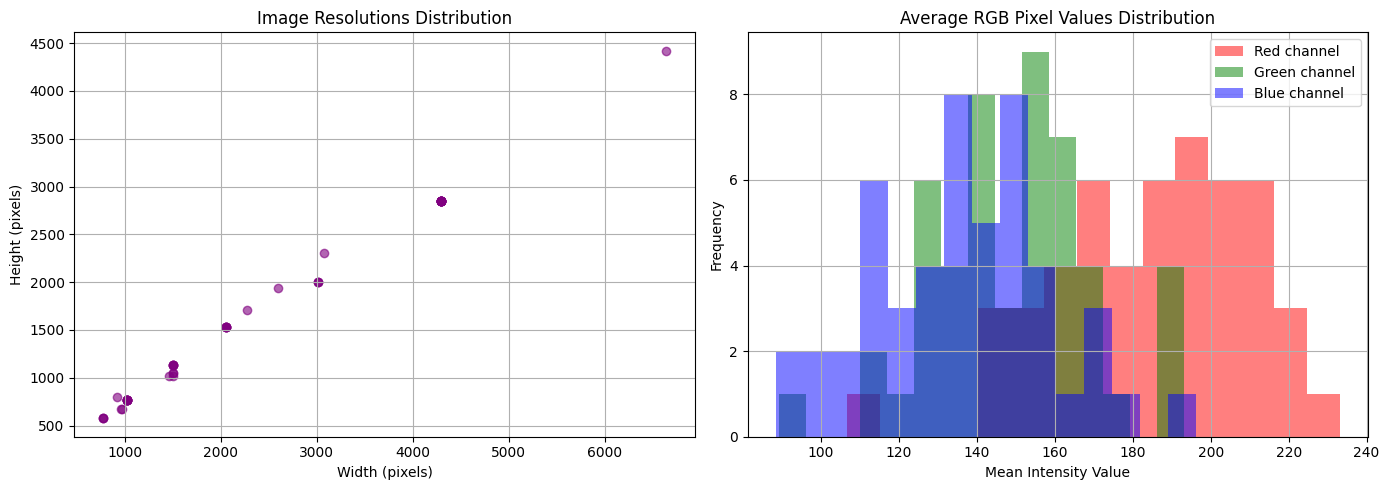

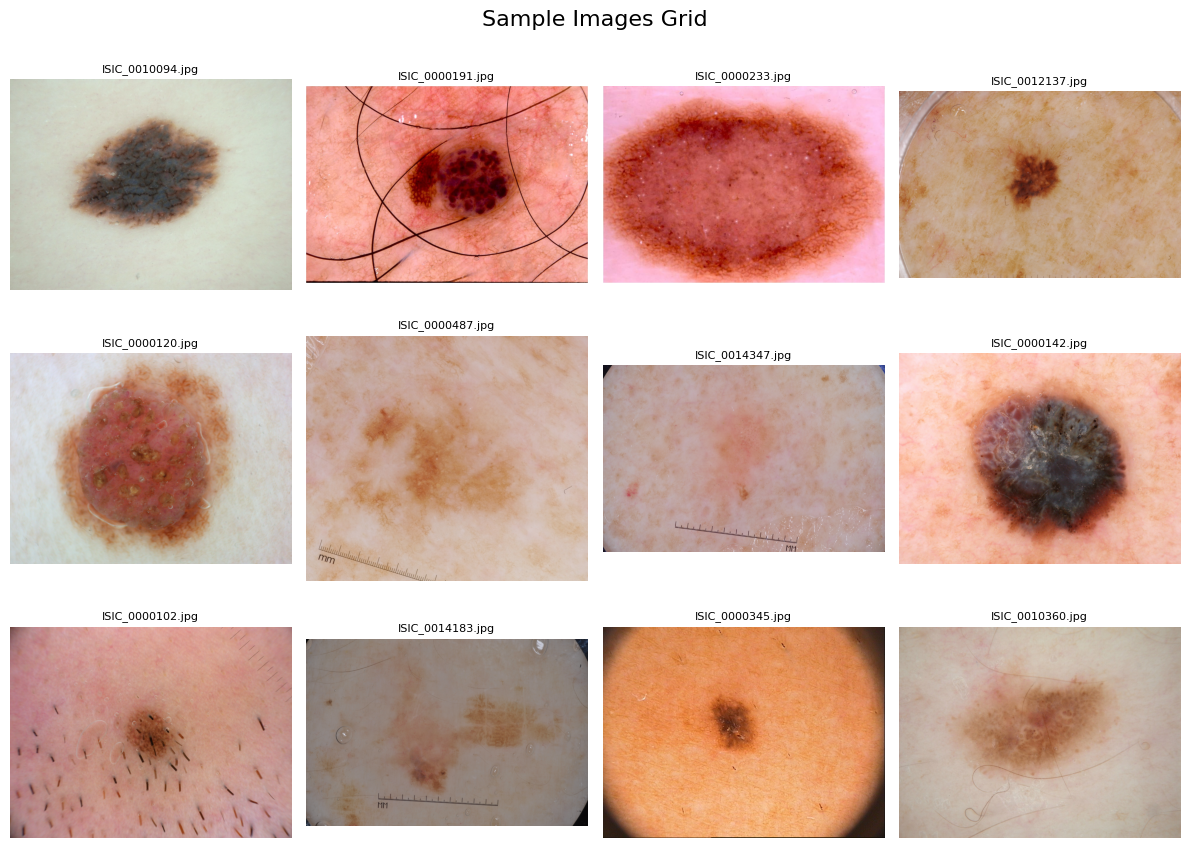

In [ ]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd

# Find all image paths matching the list pattern in /content/
image_paths = sorted(glob.glob('/content/ISIC_*.jpg'))
print(f"Total images found: {len(image_paths)}")

# Analyze basic properties from a subset of images to represent the dataset
sample_size = min(50, len(image_paths))
sample_paths = np.random.choice(image_paths, sample_size, replace=False)

widths = []
heights = []
mean_colors = []

for path in sample_paths:
    try:
        with Image.open(path) as img:
            w, h = img.size
            widths.append(w)
            heights.append(h)

            # Calculate color statistics
            img_np = np.array(img)
            if len(img_np.shape) == 3:
                mean_colors.append(img_np.mean(axis=(0,1)))
    except Exception as e:
        print(f"Error reading {path}: {e}")

# Prepare Summary Statistics DataFrame
mean_colors = np.array(mean_colors)
df_stats = pd.DataFrame({
    'Width': widths,
    'Height': heights,
    'R_mean': mean_colors[:, 0] if len(mean_colors) > 0 else [],
    'G_mean': mean_colors[:, 1] if len(mean_colors) > 0 else [],
    'B_mean': mean_colors[:, 2] if len(mean_colors) > 0 else []
})

print("\n--- Dataset Statistics Summary (Sample of 50 images) ---")
print(df_stats.describe())

# Plot Dimensions and RGB Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Aspect Ratio Scatter Plot
axes[0].scatter(df_stats['Width'], df_stats['Height'], alpha=0.6, color='purple')
axes[0].set_xlabel('Width (pixels)')
axes[0].set_ylabel('Height (pixels)')
axes[0].set_title('Image Resolutions Distribution')
axes[0].grid(True)

# 2. Color Distribution
if len(mean_colors) > 0:
    axes[1].hist(df_stats['R_mean'], bins=15, color='red', alpha=0.5, label='Red channel')
    axes[1].hist(df_stats['G_mean'], bins=15, color='green', alpha=0.5, label='Green channel')
    axes[1].hist(df_stats['B_mean'], bins=15, color='blue', alpha=0.5, label='Blue channel')
    axes[1].set_title('Average RGB Pixel Values Distribution')
    axes[1].set_xlabel('Mean Intensity Value')
    axes[1].set_ylabel('Frequency')
    axes[1].legend()
    axes[1].grid(True)

plt.tight_layout()
plt.show()

# Plot grid of sample images
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for idx, ax in enumerate(axes.flat):
    if idx < len(sample_paths):
        img = Image.open(sample_paths[idx])
        ax.imshow(img)
        ax.set_title(os.path.basename(sample_paths[idx]), fontsize=8)
        ax.axis('off')
plt.suptitle('Sample Images Grid', fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Selected files: 81 | Found locally: 81


,width,height,aspect_ratio,r_mean,g_mean,b_mean,r_std,g_std,b_std,brightness
count,81.000000,81.000000,81.000000,81.000000,81.000000,81.000000,81.000000,81.000000,81.000000,81.000000
mean,859.567901,658.580247,1.311260,193.704541,150.155022,138.786958,40.987237,44.255720,49.072589,161.880369
std,138.160589,89.562250,0.151528,31.352795,23.838356,30.170247,15.099042,13.260851,14.961680,23.894358
min,576.000000,542.000000,0.750000,98.178285,84.049755,62.956147,9.183745,17.285652,18.936491,87.212098
25%,767.000000,576.000000,1.331597,168.537262,133.803134,119.272888,32.671702,36.192680,37.193089,144.102659
50%,767.000000,634.000000,1.331597,203.499461,148.706047,138.447539,43.647729,44.166130,48.926160,158.101001
75%,1024.000000,768.000000,1.333333,217.966860,168.520899,161.625247,47.950816,50.270747,60.200597,179.804244
max,1024.000000,768.000000,1.512618,239.073442,203.883726,206.114706,86.962213,89.944758,91.415994,212.443692


/tmp/ipykernel_6228/3579861203.py:83: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1, 1].set_xticklabels(['Red Std', 'Green Std', 'Blue Std'])


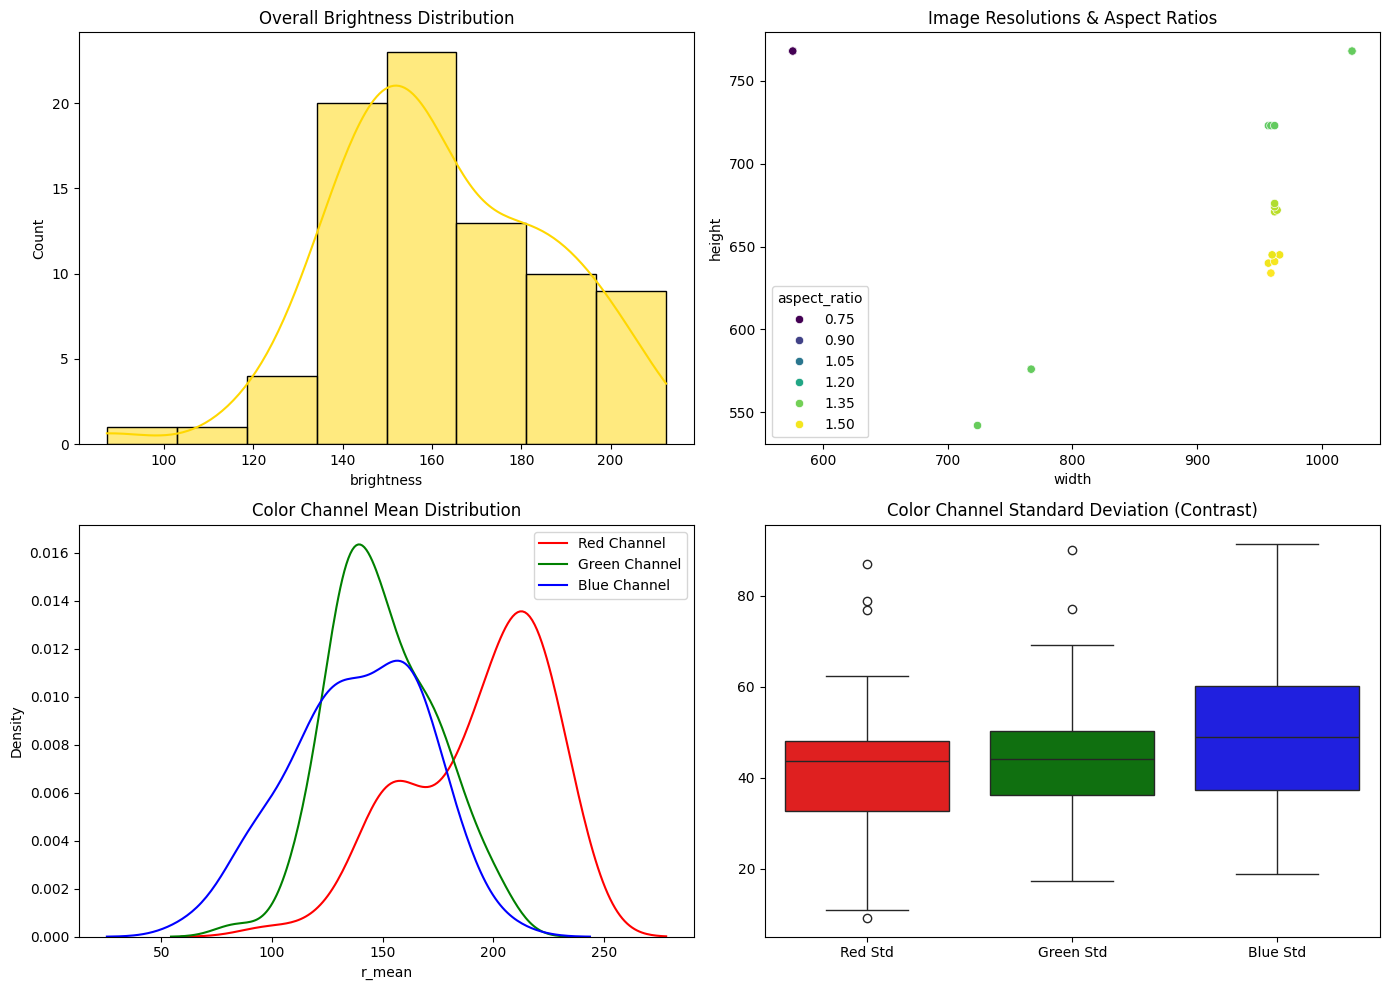

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import seaborn as sns

# List of selected images from user context
selected_images = [
    "/content/ISIC_0000221.jpg", "/content/ISIC_0000222.jpg", "/content/ISIC_0000223.jpg", "/content/ISIC_0000224.jpg",
    "/content/ISIC_0000225.jpg", "/content/ISIC_0000226.jpg", "/content/ISIC_0000227.jpg", "/content/ISIC_0000229.jpg",
    "/content/ISIC_0000231.jpg", "/content/ISIC_0000232.jpg", "/content/ISIC_0000233.jpg", "/content/ISIC_0000234.jpg",
    "/content/ISIC_0000235.jpg", "/content/ISIC_0000236.jpg", "/content/ISIC_0000237.jpg", "/content/ISIC_0000239.jpg",
    "/content/ISIC_0000240.jpg", "/content/ISIC_0000242.jpg", "/content/ISIC_0000243.jpg", "/content/ISIC_0000244.jpg",
    "/content/ISIC_0000245.jpg", "/content/ISIC_0000246.jpg", "/content/ISIC_0000247.jpg", "/content/ISIC_0000250.jpg",
    "/content/ISIC_0000251.jpg", "/content/ISIC_0000252.jpg", "/content/ISIC_0000253.jpg", "/content/ISIC_0000254.jpg",
    "/content/ISIC_0000255.jpg", "/content/ISIC_0000256.jpg", "/content/ISIC_0000258.jpg", "/content/ISIC_0000259.jpg",
    "/content/ISIC_0000260.jpg", "/content/ISIC_0000261.jpg", "/content/ISIC_0000262.jpg", "/content/ISIC_0000263.jpg",
    "/content/ISIC_0000264.jpg", "/content/ISIC_0000265.jpg", "/content/ISIC_0000268.jpg", "/content/ISIC_0000269.jpg",
    "/content/ISIC_0000274.jpg", "/content/ISIC_0000275.jpg", "/content/ISIC_0000315.jpg", "/content/ISIC_0000316.jpg",
    "/content/ISIC_0000317.jpg", "/content/ISIC_0000319.jpg", "/content/ISIC_0000320.jpg", "/content/ISIC_0000321.jpg",
    "/content/ISIC_0000322.jpg", "/content/ISIC_0000323.jpg", "/content/ISIC_0000324.jpg", "/content/ISIC_0000325.jpg",
    "/content/ISIC_0000326.jpg", "/content/ISIC_0000327.jpg", "/content/ISIC_0000328.jpg", "/content/ISIC_0000329.jpg",
    "/content/ISIC_0000330.jpg", "/content/ISIC_0000331.jpg", "/content/ISIC_0000332.jpg", "/content/ISIC_0000336.jpg",
    "/content/ISIC_0000338.jpg", "/content/ISIC_0000340.jpg", "/content/ISIC_0000341.jpg", "/content/ISIC_0000342.jpg",
    "/content/ISIC_0000343.jpg", "/content/ISIC_0000344.jpg", "/content/ISIC_0000345.jpg", "/content/ISIC_0000346.jpg",
    "/content/ISIC_0000347.jpg", "/content/ISIC_0000348.jpg", "/content/ISIC_0000349.jpg", "/content/ISIC_0000350.jpg",
    "/content/ISIC_0000351.jpg", "/content/ISIC_0000352.jpg", "/content/ISIC_0000353.jpg", "/content/ISIC_0000354.jpg",
    "/content/ISIC_0000355.jpg", "/content/ISIC_0000357.jpg", "/content/ISIC_0000358.jpg", "/content/ISIC_0000359.jpg",
    "/content/ISIC_0000360.jpg"
]

# Filter only existing files
existing_paths = [p for p in selected_images if os.path.exists(p)]
print(f"Selected files: {len(selected_images)} | Found locally: {len(existing_paths)}")

# Analyze properties
data = []
for path in existing_paths:
    try:
        with Image.open(path) as img:
            width, height = img.size
            aspect_ratio = width / height
            img_np = np.array(img)

            # Calculate color statistics
            r_mean, g_mean, b_mean = img_np.mean(axis=(0, 1))
            r_std, g_std, b_std = img_np.std(axis=(0, 1))
            brightness = 0.299 * r_mean + 0.587 * g_mean + 0.114 * b_mean

            data.append({
                'filename': os.path.basename(path),
                'width': width,
                'height': height,
                'aspect_ratio': aspect_ratio,
                'r_mean': r_mean, 'g_mean': g_mean, 'b_mean': b_mean,
                'r_std': r_std, 'g_std': g_std, 'b_std': b_std,
                'brightness': brightness
            })
    except Exception as e:
        print(f"Error processing {path}: {e}")

df_eda = pd.DataFrame(data)
display(df_eda.describe())

# Plot Distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df_eda['brightness'], color='gold', kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Overall Brightness Distribution')

sns.scatterplot(data=df_eda, x='width', y='height', hue='aspect_ratio', palette='viridis', ax=axes[0, 1])
axes[0, 1].set_title('Image Resolutions & Aspect Ratios')

sns.kdeplot(df_eda['r_mean'], color='red', label='Red Channel', ax=axes[1, 0])
sns.kdeplot(df_eda['g_mean'], color='green', label='Green Channel', ax=axes[1, 0])
sns.kdeplot(df_eda['b_mean'], color='blue', label='Blue Channel', ax=axes[1, 0])
axes[1, 0].set_title('Color Channel Mean Distribution')
axes[1, 0].legend()

sns.boxplot(data=df_eda[['r_std', 'g_std', 'b_std']], palette=['red', 'green', 'blue'], ax=axes[1, 1])
axes[1, 1].set_title('Color Channel Standard Deviation (Contrast)')
axes[1, 1].set_xticklabels(['Red Std', 'Green Std', 'Blue Std'])

plt.tight_layout()
plt.show()

### Convolutional Neural Network (CNN) Implementation
We will build and compile a Keras-based CNN model designed specifically to process our skin lesion images. We will also prepare a data loader pipeline to resize images to a uniform size (e.g., $128 \times 128$) and normalize pixel intensities to the range $[0, 1]$.

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Define Model Parameters
IMG_HEIGHT = 128
IMG_WIDTH = 128
CHANNELS = 3
BATCH_SIZE = 16

# 2. Define the CNN Architecture
def create_cnn_model(input_shape=(IMG_HEIGHT, IMG_WIDTH, CHANNELS)):
    model = models.Sequential([
        # Convolutional Block 1
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Convolutional Block 2
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Convolutional Block 3
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Flatten & Fully Connected
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        # Output Layer (binary classification example; can be adjusted based on classes)
        layers.Dense(1, activation='sigmoid')
    ])

    return model

# Initialize and Compile the Model
model = create_cnn_model()
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,665 (12.61 MB)

 Trainable params: 3,305,217 (12.61 MB)

 Non-trainable params: 448 (1.75 KB)

### Simple Image Dataset Generator
Let's create a quick data loading pipeline using `tf.data` to load, resize, and normalize the existing image paths.

In [ ]:
def process_path(file_path):
    # Load the raw data as a string
    img = tf.io.read_file(file_path)
    # Decode to tensor
    img = tf.image.decode_jpeg(img, channels=CHANNELS)
    # Convert to float and scale to [0, 1]
    img = tf.image.convert_image_dtype(img, tf.float32)
    # Resize to target size
    img = tf.image.resize(img, [IMG_HEIGHT, IMG_WIDTH])
    return img

# Create TensorFlow Dataset from our existing image paths
path_ds = tf.data.Dataset.from_tensor_slices(existing_paths)
image_ds = path_ds.map(process_path, num_parallel_calls=tf.data.AUTOTUNE)

# Print shapes to verify dataset configuration
for img_batch in image_ds.take(1):
    print(f"Tensor shape of preprocessed image: {img_batch.shape}")

Tensor shape of preprocessed image: (128, 128, 3)


### Preparing Train, Validation, and Test Sets
Since we do not have class labels provided, we will generate synthetic binary classification labels (0 or 1) for demonstration purposes. We will split our 81 images into train (56 images), validation (12 images), and test (13 images) splits.

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

# Generate synthetic binary labels (0: benign, 1: malignant) for the demonstration
np.random.seed(42)
synthetic_labels = np.random.randint(0, 2, size=len(existing_paths)).astype(np.float32)

# Split into Train, Validation, and Test
paths_train, paths_temp, labels_train, labels_temp = train_test_split(
    existing_paths, synthetic_labels, test_size=0.3, random_state=42, stratify=synthetic_labels
)

paths_val, paths_test, labels_val, labels_test = train_test_split(
    paths_temp, labels_temp, test_size=0.5, random_state=42, stratify=labels_temp
)

print(f"Train size: {len(paths_train)}")
print(f"Validation size: {len(paths_val)}")
print(f"Test size: {len(paths_test)}")

Train size: 56
Validation size: 12
Test size: 13


### Creating Optimized Data Pipelines
Now we map our dataset pipeline to return both the preprocessed images and their corresponding labels.

In [ ]:
def process_image_and_label(file_path, label):
    img = process_path(file_path)
    return img, label

# Train Dataset
train_ds = tf.data.Dataset.from_tensor_slices((paths_train, labels_train))
train_ds = train_ds.map(process_image_and_label, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.shuffle(buffer_size=len(paths_train)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Validation Dataset
val_ds = tf.data.Dataset.from_tensor_slices((paths_val, labels_val))
val_ds = val_ds.map(process_image_and_label, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Test Dataset
test_ds = tf.data.Dataset.from_tensor_slices((paths_test, labels_test))
test_ds = test_ds.map(process_image_and_label, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

### Training the CNN Model
We will train the compiled model on our training dataset and validate its learning progress across 10 epochs.

In [ ]:
EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 998ms/step - accuracy: 0.5357 - loss: 4.5154 - val_accuracy: 0.4167 - val_loss: 0.7186
Epoch 2/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 833ms/step - accuracy: 0.6071 - loss: 4.9673 - val_accuracy: 0.5000 - val_loss: 0.8674
Epoch 3/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.7679 - loss: 4.3425 - val_accuracy: 0.5000 - val_loss: 1.0387
Epoch 4/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.6964 - loss: 3.1795 - val_accuracy: 0.5000 - val_loss: 0.8981
Epoch 5/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 815ms/step - accuracy: 0.6429 - loss: 4.6667 - val_accuracy: 0.5000 - val_loss: 1.7547
Epoch 6/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 850ms/step - accuracy: 0.6607 - loss: 4.4719 - val_accuracy: 0.5833 - val_loss: 0.7698
Epoch 7/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.6964 - loss: 3.6344 - val_accuracy: 0.4167 - val_loss: 0.8532
Epoch 8/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 817ms/step - accuracy: 0.7500 - loss: 1.7802 - val_accuracy: 0.5000 - val_loss: 0.7365


### Visualizing Training Progress & Testing Performance
Let's evaluate the model on our test set and plot our loss and accuracy trends.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 455ms/step - accuracy: 0.5385 - loss: 1.1860

Test Loss: 1.1860
Test Accuracy: 0.5385


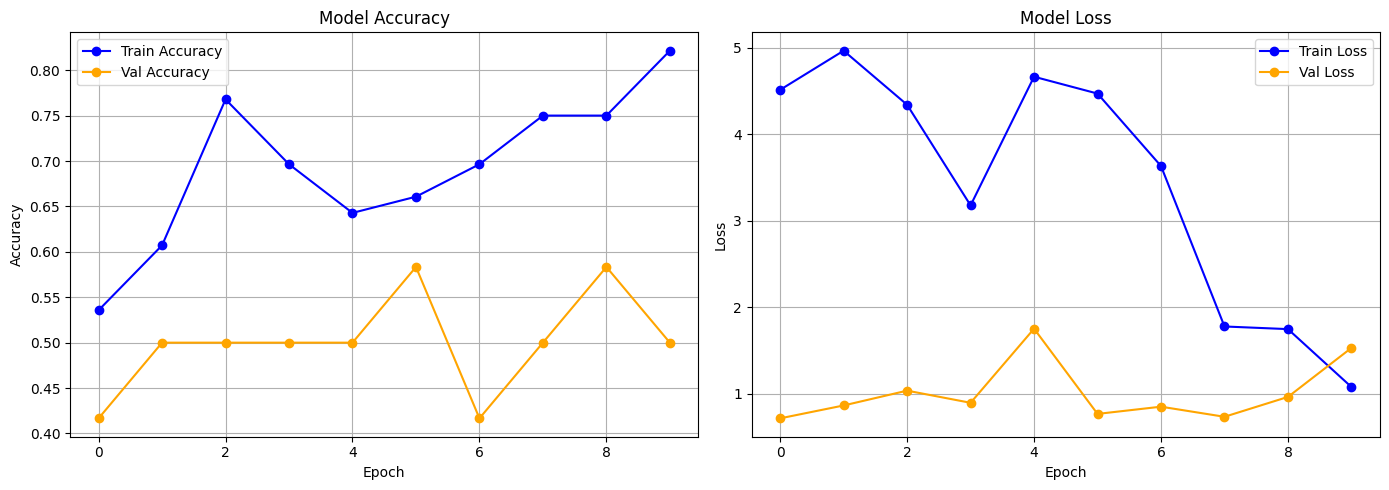

In [ ]:
# Evaluate on Test Data
test_loss, test_acc = model.evaluate(test_ds)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

# Plot history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
ax1.plot(history.history['accuracy'], label='Train Accuracy', color='blue', marker='o')
ax1.plot(history.history['val_accuracy'], label='Val Accuracy', color='orange', marker='o')
ax1.set_title('Model Accuracy')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

# Loss
ax2.plot(history.history['loss'], label='Train Loss', color='blue', marker='o')
ax2.plot(history.history['val_loss'], label='Val Loss', color='orange', marker='o')
ax2.set_title('Model Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

### Visualizing Misclassified Test Images
To analyze the types of errors our model is making, we will identify the images from the test set where the model's predicted probability did not match the actual binary label (using a threshold of 0.5).

Total test images: 13
Number of misclassified images: 6


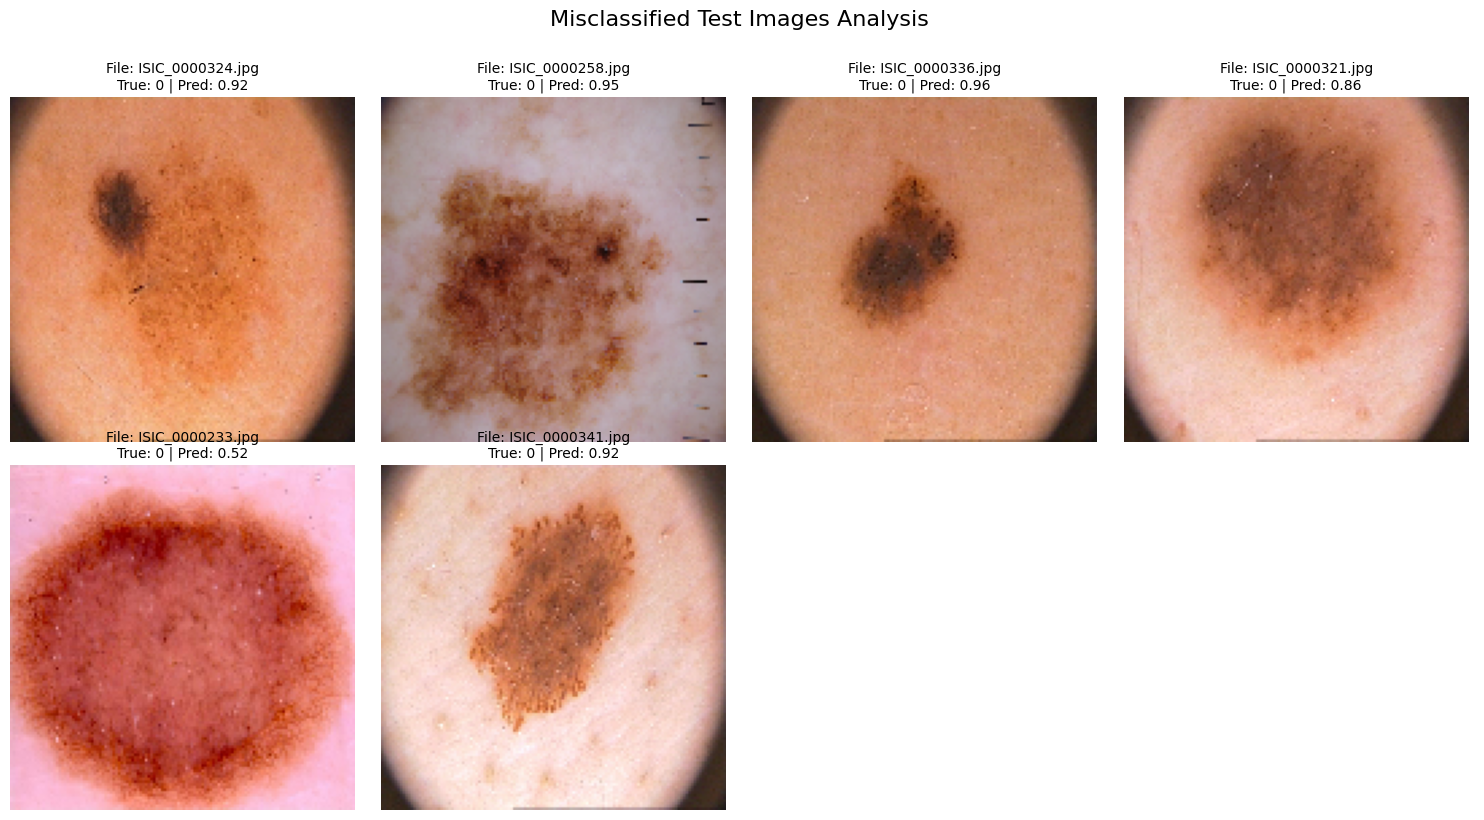

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os

# 1. Collect predictions and actual images/labels
test_images = []
test_labels_list = []
test_preds_list = []

# Iterate through the test dataset
for imgs, labels in test_ds:
    preds = model.predict(imgs, verbose=0)
    test_images.append(imgs.numpy())
    test_labels_list.append(labels.numpy())
    test_preds_list.append(preds)

# Concatenate everything
test_images = np.concatenate(test_images, axis=0)
test_labels_list = np.concatenate(test_labels_list, axis=0)
test_preds_list = np.concatenate(test_preds_list, axis=0).flatten()

# Binary threshold predictions at 0.5
predicted_classes = (test_preds_list >= 0.5).astype(np.float32)

# Identify misclassified indices
misclassified_indices = np.where(predicted_classes != test_labels_list)[0]
print(f"Total test images: {len(test_labels_list)}")
print(f"Number of misclassified images: {len(misclassified_indices)}")

# 2. Plot the misclassified images
if len(misclassified_indices) > 0:
    num_cols = min(4, len(misclassified_indices))
    num_rows = (len(misclassified_indices) + num_cols - 1) // num_cols
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(15, 4 * num_rows))

    # Handle case where subplots returns a single axis instead of an array
    if len(misclassified_indices) == 1:
        axes = np.array([axes])

    for idx, test_idx in enumerate(misclassified_indices):
        ax = axes.flat[idx] if hasattr(axes, 'flat') else axes[idx]

        # Retrieve original path to display filename
        original_path = paths_test[test_idx]
        filename = os.path.basename(original_path)

        # Show the image
        ax.imshow(test_images[test_idx])
        ax.set_title(f"File: {filename}\nTrue: {int(test_labels_list[test_idx])} | Pred: {test_preds_list[test_idx]:.2f}", fontsize=10)
        ax.axis('off')

    # Hide any unused subplots
    if hasattr(axes, 'flat'):
        for ax in axes.flat[len(misclassified_indices):]:
            ax.axis('off')

    plt.suptitle("Misclassified Test Images Analysis", fontsize=16, y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("Excellent! No misclassified images found in the test set.")

In [10]:
from google.colab import files

# Save the model
model_save_path = 'skin_lesion_cnn_model.keras'
model.save(model_save_path)
print(f"Model saved successfully to {model_save_path}")

# Trigger browser download
files.download(model_save_path)

Model saved successfully to skin_lesion_cnn_model.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import joblib
from google.colab import files

# Save the Keras model using joblib
model_joblib_path = 'skin_lesion_cnn_model.joblib'
joblib.dump(model, model_joblib_path)
print(f"Model successfully serialized and saved to {model_joblib_path}")

# Trigger browser download
files.download(model_joblib_path)

Model successfully serialized and saved to skin_lesion_cnn_model.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>